# Tarea 2 · Parte 2 — Evaluación de modelos y extracción estructurada

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Estudiante** | Eliana Camacho (@ecamachoro-bit) |
| **Muestra fija** | 10 documentos (2 impresos, 5 fotos, 3 manuscritos) y 10 clips (marcha, exteriores, estadio y testimonios grabados), elegidos en `datos/muestra_evaluacion.csv` **antes** de calcular cualquier métrica |
| **Referencias** | Transcripción manual hecha por la estudiante en `datos/referencias/<id>.txt`, escuchando el audio o mirando la imagen original (no se corrigió la salida de ningún modelo) |
| **OCR comparados** | PaddleOCR 3.7 (línea base, sin personalización) vs. Tesseract 5 (`spa`, tessdata_fast) |
| **ASR comparados** | faster-whisper `small` (línea base, CPU) vs. Whisper large-v3-turbo + VAD (modelo del pipeline) vs. NVIDIA Parakeet TDT 0.6B v3 |
| **LLM** | Gemini 3.5 Flash-Lite (`temperature=0`, salida JSON) sobre los 53 textos seudonimizados |

**Reglas de la evaluación:** los tres ASR y los dos OCR se ejecutaron sobre exactamente los mismos archivos, con configuraciones fijadas en `procesar_evaluacion.py` antes de ver los resultados. No se ajustó ningún parámetro mirando estas métricas.

In [1]:
import json
import warnings
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

import voz

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+png"   # interactivo en Jupyter y PNG visible en GitHub
pd.set_option("display.max_colwidth", 90)

DATOS = Path("datos")
docs = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
aud = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)
muestra = pd.read_csv(DATOS / "muestra_evaluacion.csv")
muestra.groupby(["modalidad", "tipo_o_condicion"]).size().rename("n").to_frame()

n
modalidad tipo_o_condicion             
audio     estadio (ruido)             1
          exteriores                  2
          marcha (ruido de multitud)  1
          testimonio grabado          6
documento foto                        5
          impreso                     2
          manuscrito                  3

## 1. Muestra de evaluación y referencias manuales

Las transcripciones manuales están en `datos/referencias/`. Criterios de transcripción, iguales para todos los archivos:

- Se transcribe **lo que se ve o se oye**, con la ortografía original del documento (*Relijion*, *Nacion*), sin corregirla.
- En audio no se transcriben muletillas inaudibles ni ruido; las palabras cortadas se omiten.
- Los nombres de personas privadas se escriben con el **mismo seudónimo** `[PERSONA_nn]` que usa el corpus publicado, para que la referencia también sea publicable.
- No se escriben marcas de hablante: el WER mide solo palabras habladas.

La celda siguiente carga las referencias y las guarda en la columna `texto_referencia` de los dos CSV (vacía para los archivos fuera de la muestra).

In [2]:
refs = {i: (DATOS / "referencias" / f"{i}.txt").read_text(encoding="utf-8").strip() for i in muestra["id"]}
faltan = [i for i, t in refs.items() if not t]
assert not faltan, f"Faltan transcripciones manuales en datos/referencias/: {faltan}"

docs["texto_referencia"] = docs["id"].map(refs).fillna("")
aud["texto_referencia"] = aud["id"].map(refs).fillna("")
docs.to_csv(DATOS / "documentos.csv", index=False)
aud.to_csv(DATOS / "transcripciones.csv", index=False)

muestra["palabras_referencia"] = muestra["id"].map(lambda i: len(refs[i].split()))
muestra["caracteres_referencia"] = muestra["id"].map(lambda i: len(refs[i]))
print("Documentos con referencia:", (docs["texto_referencia"] != "").sum(), "| clips con referencia:", (aud["texto_referencia"] != "").sum())
muestra

Documentos con referencia: 10 | clips con referencia: 10


,id,modalidad,tipo_o_condicion,motivo,palabras_referencia,caracteres_referencia
0,doc_002,documento,impreso,Constitución de 1823: impreso antiguo con ortografía de época (j por g),154,928
1,doc_008,documento,impreso,Informe de 1903: impreso nítido moderno,117,635
2,doc_009,documento,foto,Texto en escaleras: inclinación fuerte y reflejos,40,209
3,doc_010,documento,foto,Texto en vidrio: reflejos y fondo oscuro,12,61
4,doc_011,documento,foto,Cartel de Barranco: brillo y texto bilingüe,14,63
5,doc_012,documento,foto,Página de libro con sombra y curvatura,114,675
6,doc_014,documento,foto,Sumario con columnas de números e inclinación,50,299
7,doc_017,documento,manuscrito,Manuscrito propio 1,17,107
8,doc_018,documento,manuscrito,Manuscrito propio 2,8,45
9,doc_019,documento,manuscrito,Manuscrito propio 3,30,176


## 2. Normalización y salidas de cada modelo

Referencias e hipótesis pasan por **la misma** función `voz.normalizar` (minúsculas, sin puntuación, tildes conservadas). Antes se quitan las marcas `[HABLANTE_n]`, que no son palabras habladas. El CER y el WER globales se calculan sobre el conjunto de los 10 archivos (errores totales / longitud total de las referencias), y también por archivo para ver los casos difíciles.

Las salidas de los modelos alternativos y de la línea base se generaron con `procesar_evaluacion.py` y están en `datos/salidas_eval/`. Los tiempos de PaddleOCR y de Whisper turbo provienen de los respaldos crudos de la Parte 1.

In [3]:
import re

def limpiar(texto):
    return re.sub(r"\[HABLANTE_\d+\]", " ", str(texto))

ids_doc = muestra.query("modalidad == 'documento'")["id"].tolist()
ids_aud = muestra.query("modalidad == 'audio'")["id"].tolist()
grupo = muestra.set_index("id")["tipo_o_condicion"]

def segundos_paddle(i):
    return json.loads(Path(f"datos/raw/documentos/ocr/{i}.json").read_text(encoding="utf-8"))["segundos"]

def segundos_turbo(i):
    return json.loads(Path(f"datos/raw/audio/salidas/{i}.json").read_text(encoding="utf-8"))["segundos_proceso"]

tess = pd.read_csv(DATOS / "salidas_eval" / "tesseract.csv", keep_default_na=False).set_index("id")
small = pd.read_csv(DATOS / "salidas_eval" / "whisper_small.csv", keep_default_na=False).set_index("id")
para = pd.read_csv(DATOS / "salidas_eval" / "parakeet_v3.csv", keep_default_na=False).set_index("id")
d_docs, d_aud = docs.set_index("id"), aud.set_index("id")

salidas = {   # modelo -> (modalidad, rol, textos por id, segundos por id, segundos de carga)
    "PaddleOCR 3.7 (base)": ("documento", "línea base", d_docs["texto_ocr"], {i: segundos_paddle(i) for i in ids_doc}, None),
    "Tesseract 5 spa": ("documento", "alternativo", tess["texto"], tess["segundos"], None),
    "faster-whisper small (base)": ("audio", "línea base", small["texto"], small["segundos"], small["carga_seg"].iloc[0]),
    "Whisper large-v3-turbo + VAD": ("audio", "pipeline", d_aud["texto_asr"], {i: segundos_turbo(i) for i in ids_aud}, None),
    "Parakeet TDT 0.6B v3": ("audio", "alternativo", para["texto"], para["segundos"], para["carga_seg"].iloc[0]),
}
assert all(set(ids_doc if m == "documento" else ids_aud) <= set(t.index) for m, _, t, _, _ in salidas.values())

## 3. CER y WER sobre la muestra fija

In [4]:
filas, detalle = [], []
for modelo, (modalidad, rol, textos, segs, carga) in salidas.items():
    ids = ids_doc if modalidad == "documento" else ids_aud
    metrica, f = ("CER", voz.cer) if modalidad == "documento" else ("WER", voz.wer)
    ref = [refs[i] for i in ids]
    hip = [limpiar(textos[i]) for i in ids]
    for i, r, h in zip(ids, ref, hip):
        detalle.append({"id": i, "modalidad": modalidad, "grupo": grupo[i], "modelo": modelo, "métrica": metrica, "valor": round(f([r], [h]), 4)})
    total_seg = sum(float(segs[i]) for i in ids)
    fila = {"modalidad": modalidad, "modelo": modelo, "rol": rol, "métrica": metrica, "CER/WER": round(f(ref, hip), 3),
            "segundos_totales": round(total_seg, 1), "segundos_por_archivo": round(total_seg / len(ids), 1)}
    if modalidad == "audio":
        dur = d_aud.loc[ids, "duracion_seg"].sum()
        fila["factor_tiempo_real"] = round(total_seg / dur, 2)
        fila["carga_modelo_seg"] = carga
    filas.append(fila)

metricas = pd.DataFrame(filas)
metricas_detalle = pd.DataFrame(detalle)
metricas.to_csv(DATOS / "metricas.csv", index=False)
metricas_detalle.to_csv(DATOS / "metricas_detalle.csv", index=False)
metricas

,modalidad,modelo,rol,métrica,CER/WER,segundos_totales,segundos_por_archivo,factor_tiempo_real,carga_modelo_seg
0,documento,PaddleOCR 3.7 (base),línea base,CER,0.086,358.0,35.8,NaN,NaN
1,documento,Tesseract 5 spa,alternativo,CER,0.193,17.9,1.8,NaN,NaN
2,audio,faster-whisper small (base),línea base,WER,0.178,290.2,29.0,0.67,3.8
3,audio,Whisper large-v3-turbo + VAD,pipeline,WER,0.116,524.7,52.5,1.21,NaN
4,audio,Parakeet TDT 0.6B v3,alternativo,WER,0.201,196.0,19.6,0.45,187.6


El **factor de tiempo real** (RTF) es el tiempo de proceso dividido entre la duración del audio: menos de 1 significa que el modelo transcribe más rápido de lo que dura la grabación. Todo se midió en la misma laptop, en CPU.

In [5]:
base_cer = metricas.query("modelo == 'PaddleOCR 3.7 (base)'")["CER/WER"].iloc[0]
base_wer = metricas.query("modelo == 'faster-whisper small (base)'")["CER/WER"].iloc[0]
print(f"Línea base — CER PaddleOCR: {base_cer:.3f} | WER faster-whisper small: {base_wer:.3f}")

Línea base — CER PaddleOCR: 0.086 | WER faster-whisper small: 0.178


## 4. Casos difíciles: error por tipo de documento y condición de grabación

In [6]:
por_grupo = (metricas_detalle.groupby(["modalidad", "grupo", "modelo"])["valor"].mean().round(3)
             .unstack("modelo"))
por_grupo

modelo                                PaddleOCR 3.7 (base)  \
modalidad grupo                                              
audio     estadio (ruido)                              NaN   
          exteriores                                   NaN   
          marcha (ruido de multitud)                   NaN   
          testimonio grabado                           NaN   
documento foto                                       0.220   
          impreso                                    0.066   
          manuscrito                                 0.160   

modelo                                Parakeet TDT 0.6B v3  Tesseract 5 spa  \
modalidad grupo                                                               
audio     estadio (ruido)                            0.410              NaN   
          exteriores                                 0.266              NaN   
          marcha (ruido de multitud)                 0.329              NaN   
          testimonio grabado                         0.065              NaN   
documento foto                                         NaN            0.349   
          impreso                                      NaN            0.017   
          manuscrito                                   NaN            0.992   

modelo                                Whisper large-v3-turbo + VAD  \
modalidad grupo                                                      
audio     estadio (ruido)                                    0.333   
          exteriores                                         0.126   
          marcha (ruido de multitud)                         0.110   
          testimonio grabado                                 0.069   
documento foto                                                 NaN   
          impreso                                              NaN   
          manuscrito                                           NaN   

modelo                                faster-whisper small (base)  
modalidad grupo                                                    
audio     estadio (ruido)                                   0.256  
          exteriores                                        0.219  
          marcha (ruido de multitud)                        0.233  
          testimonio grabado                                0.101  
documento foto                                                NaN  
          impreso                                             NaN  
          manuscrito                                          NaN

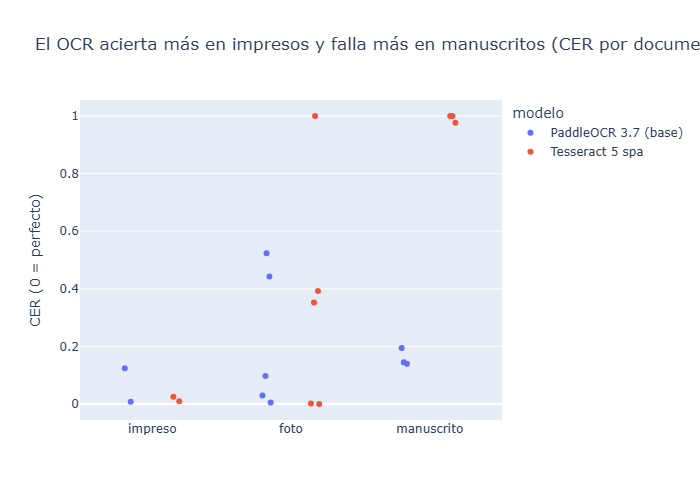

In [7]:
cer_det = metricas_detalle.query("métrica == 'CER'")
mejor_tipo = cer_det.groupby("grupo")["valor"].mean().idxmin()
peor_tipo = cer_det.groupby("grupo")["valor"].mean().idxmax()
fig = px.strip(cer_det, x="grupo", y="valor", color="modelo", hover_data=["id"],
               category_orders={"grupo": ["impreso", "foto", "manuscrito"]},
               title=f"El OCR acierta más en {mejor_tipo}s y falla más en {peor_tipo}s (CER por documento)")
fig.update_layout(xaxis_title="", yaxis_title="CER (0 = perfecto)")
fig.show()

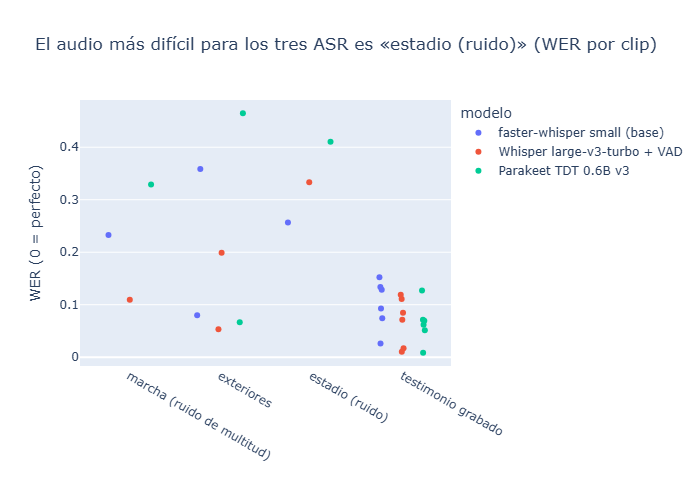

In [8]:
wer_det = metricas_detalle.query("métrica == 'WER'")
peor_cond = wer_det.groupby("grupo")["valor"].mean().idxmax()
fig = px.strip(wer_det, x="grupo", y="valor", color="modelo", hover_data=["id"],
               title=f"El audio más difícil para los tres ASR es «{peor_cond}» (WER por clip)")
fig.update_layout(xaxis_title="", yaxis_title="WER (0 = perfecto)")
fig.show()

Los peores casos de cada modalidad, con la referencia junto a la salida de cada modelo:

In [9]:
def comparar(i):
    modelos = [m for m, v in salidas.items() if v[0] == ("documento" if i.startswith("doc") else "audio")]
    tabla = pd.DataFrame({"texto": {"Referencia manual": refs[i], **{m: limpiar(salidas[m][2][i]) for m in modelos}}})
    tabla["error"] = [None] + metricas_detalle.query("id == @i").set_index("modelo").loc[modelos, "valor"].tolist()
    return tabla

for i in [cer_det.groupby("id")["valor"].mean().idxmax(), wer_det.groupby("id")["valor"].mean().idxmax()]:
    print(f"\n=== {i} · {grupo[i]} · {muestra.set_index('id').loc[i, 'motivo']}")
    display(comparar(i))


=== doc_010 · foto · Texto en vidrio: reflejos y fondo oscuro


,texto,error
Referencia manual,no sé\nsi he cazado\nuna luciérnaga\no he alcanzado\nuna estrella,NaN
PaddleOCR 3.7 (base),se no cazado si he una ohe alcanzad una estre rella 7,0.4426
Tesseract 5 spa,,1.0000



=== clip_009 · exteriores · Entrevista a una señora en Pomabamba


,texto,error
Referencia manual,"-¿Cuál es su nombre? \n- [PERSONA_10]\n- Ah, okay. Usted, este... me acaba de decir qu...",NaN
faster-whisper small (base),¿Cuál es tu nombre? Vina Espenosa ¿Usted me acaba de decir que no eres el pueblo? ¿Ust...,0.3584
Whisper large-v3-turbo + VAD,"¿Cuál es su nombre? [PERSONA_10]. Ah, ok. Usted, este, me acaba de decir que no es del...",0.1991
Parakeet TDT 0.6B v3,"¿Cuál se nombra? Ah, okay. Usted este me acaba de decir que no es del pueblo. Usted de...",0.4646


Tablas de apoyo para el dashboard: los textos de los modelos alternativos sobre la muestra (`datos/ocr_alternativo.csv` y `datos/asr_alternativos.csv`).

In [10]:
pd.DataFrame({"id": ids_doc, "Tesseract": [tess.loc[i, "texto"] for i in ids_doc]}).to_csv(DATOS / "ocr_alternativo.csv", index=False)
pd.DataFrame({"id": ids_aud, "Whisper small": [small.loc[i, "texto"] for i in ids_aud],
              "Parakeet v3": [para.loc[i, "texto"] for i in ids_aud]}).to_csv(DATOS / "asr_alternativos.csv", index=False)
print("Guardados ocr_alternativo.csv y asr_alternativos.csv")

Guardados ocr_alternativo.csv y asr_alternativos.csv


## 5. Extracción estructurada con LLM

`extraer_llm.py` envía cada texto seudonimizado a Gemini con un prompt que fija las claves del JSON:

- **Todos:** `modalidad`, `tema`, `resumen`, `idioma`.
- **Documentos:** `tipo_documento`, `emisor`, `fecha`, `monto`, solo si aparecen en el texto.
- **Audios:** `numero_hablantes` (solo si se sustenta con marcas de hablante o un diálogo evidente) y `citas_clave` (1 a 3 citas literales).

La regla es usar `null` cuando el dato no aparece y no inventar. Las respuestas quedan guardadas en `datos/salidas_llm/` (caché) y se consolidan en `datos/extraccion_llm.csv`.

In [11]:
llm = pd.read_csv(DATOS / "extraccion_llm.csv", keep_default_na=False)
campos = pd.DataFrame([{"id": r.id, "modalidad": r.modalidad, **json.loads(r.campos_json)} for r in llm.itertuples()], dtype=object)
print(llm.shape, "| modelo:", llm["modelo_llm"].unique()[0], "| fecha:", llm["fecha"].unique()[0])
llm.head()

(53, 5) | modelo: gemini-3.5-flash-lite (temperature=0, salida JSON) | fecha: 2026-10-26


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""sabiduría divina y humildad humana"", ""resumen"": ""E...","gemini-3.5-flash-lite (temperature=0, salida JSON)",2026-10-26
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución y religión del Perú"", ""resumen"": ""El ...","gemini-3.5-flash-lite (temperature=0, salida JSON)",2026-10-26
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Funcionamiento de los colegios electorales"", ""resu...","gemini-3.5-flash-lite (temperature=0, salida JSON)",2026-10-26
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""principios constitucionales y derechos fundamental...","gemini-3.5-flash-lite (temperature=0, salida JSON)",2026-10-26
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Diario de viaje por el Río Bermejo"", ""resumen"": ""F...","gemini-3.5-flash-lite (temperature=0, salida JSON)",2026-10-26


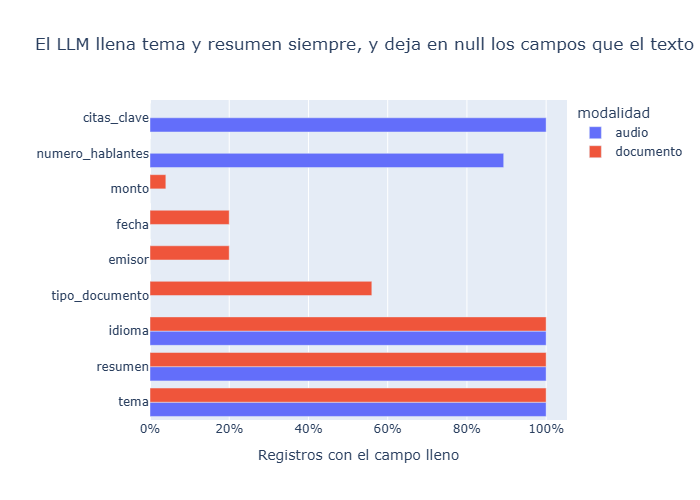

In [12]:
llenos = (campos.drop(columns=["id", "modalidad"]).notna() & campos.drop(columns=["id", "modalidad"]).ne(""))
llenado = llenos.groupby(campos["modalidad"]).mean().T.reset_index(names="campo").melt(id_vars="campo", var_name="modalidad", value_name="proporción")
fig = px.bar(llenado.dropna(), x="proporción", y="campo", color="modalidad", barmode="group", orientation="h",
             title="El LLM llena tema y resumen siempre, y deja en null los campos que el texto no sustenta")
fig.update_layout(xaxis_tickformat=".0%", yaxis_title="", xaxis_title="Registros con el campo lleno")
fig.show()

## 6. Auditoría humana de 20 extracciones

Se sortean **10 documentos y 10 audios** del corpus completo (`random_state=42`). Para cada uno, la estudiante leyó el texto OCR/ASR (y la imagen o el audio cuando hizo falta) y marcó la extracción como **completamente correcta (1)** solo si cumple todo lo siguiente:

1. `tema` y `resumen` describen fielmente el texto, sin agregar hechos.
2. Todo campo con valor está sustentado explícitamente en el texto (fechas, emisores, montos, citas literales).
3. Ningún dato que sí aparece claramente quedó en `null`.
4. Los seudónimos `[PERSONA_nn]` se respetan.

Si falla cualquiera, se marca **0** y se anota el error en `errores`. La revisión está en `datos/auditoria_llm.csv`.

In [13]:
ruta = DATOS / "auditoria_llm.csv"
if not ruta.exists():
    sorteo = pd.concat([campos[campos["modalidad"] == m].sample(10, random_state=42) for m in ["documento", "audio"]])
    plantilla = sorteo[["id", "modalidad", "tema", "resumen"]].merge(llm[["id", "campos_json"]], on="id")
    plantilla["correcto"], plantilla["errores"] = "", ""
    plantilla.to_csv(ruta, index=False)
    print("Se creó la plantilla", ruta, "— completar las columnas 'correcto' (1/0) y 'errores' y volver a ejecutar.")

auditoria = pd.read_csv(ruta, keep_default_na=False)
assert len(auditoria) == 20 and auditoria["correcto"].astype(str).isin(["0", "1"]).all(), "Falta completar la auditoría"
auditoria["correcto"] = auditoria["correcto"].astype(int)
ok = auditoria["correcto"].sum()
print(f"Extracciones completamente correctas: {ok}/20 ({ok / 20:.0%})")
print(auditoria.groupby("modalidad")["correcto"].agg(["sum", "count"]))
auditoria.query("correcto == 0")[["id", "modalidad", "errores"]]

Extracciones completamente correctas: 9/20 (45%)
           sum  count
modalidad            
audio        3     10
documento    6     10


,id,modalidad,errores
0,doc_009,documento,"el resumen generaliza: el texto dice ""te defiendo"" (a quien pregunta), no ""a los demás"""
1,doc_017,documento,"emisor ""Shakespeiane"" copia el error del OCR; el autor es Shakespeare (el propio resum..."
7,doc_002,documento,"el resumen dice ""ciudadanos peruanos"" pero el Art. 10 define quiénes son ""Peruanos"" (n..."
9,doc_006,documento,"el resumen agrega ""Amazonas"", que no aparece en el texto (dato correcto pero externo a..."
11,clip_026,audio,"el resumen exagera: el hablante dice que su infancia fue ""muy bonita"" con ""un poco de ..."
13,clip_022,audio,"el resumen atribuye ""sin su consentimiento"" a la maniobra de Kristeller, pero en el au..."
14,clip_001,audio,"el tema dice ""en Lima"" pero el audio solo menciona Plaza San Martín (y también ""aquí e..."
15,clip_013,audio,"el resumen atribuye la histerectomía a ""mala praxis"", pero el audio dice que fue ""por ..."
16,clip_018,audio,"el tema dice ""hospital peruano"" pero el audio no menciona el país; es una deducción ex..."
18,clip_012,audio,"el resumen afirma que el maltrato ""resultó en"" complicaciones para el bebé, pero el au..."


## 7. Comparativa final y decisión

In [14]:
tabla = metricas[["modalidad", "modelo", "rol", "métrica", "CER/WER", "segundos_por_archivo", "factor_tiempo_real"]].copy()
tabla["mejora_vs_base"] = tabla.apply(lambda r: round((base_cer if r["métrica"] == "CER" else base_wer) - r["CER/WER"], 3), axis=1)
tabla

,modalidad,modelo,rol,métrica,CER/WER,segundos_por_archivo,factor_tiempo_real,mejora_vs_base
0,documento,PaddleOCR 3.7 (base),línea base,CER,0.086,35.8,NaN,0.000
1,documento,Tesseract 5 spa,alternativo,CER,0.193,1.8,NaN,-0.107
2,audio,faster-whisper small (base),línea base,WER,0.178,29.0,0.67,0.000
3,audio,Whisper large-v3-turbo + VAD,pipeline,WER,0.116,52.5,1.21,0.062
4,audio,Parakeet TDT 0.6B v3,alternativo,WER,0.201,19.6,0.45,-0.023


## Decisión y reflexión

### OCR → PaddleOCR

CER global **0,086** frente a **0,193** de Tesseract. Tesseract gana en impresos nítidos (0,017 vs. 0,066) y es unas 20 veces más rápido (1,8 s frente a 35,8 s por página en CPU), pero se derrumba fuera de ese caso: en los 3 manuscritos su CER es **0,99** (casi no reconoce nada) y en doc_010 (texto sobre vidrio) devuelve una cadena vacía. PaddleOCR, cuyo detector está entrenado para texto en escenas, mantiene un CER de 0,14 a 0,19 en manuscritos. Para un archivo mixto real conviene PaddleOCR; si el archivo fuera solo de impresos limpios, Tesseract sería la opción barata.

- **Mejor desempeño: impresos** (CER 0,066; doc_008 y doc_012 por debajo de 0,01).
- **Peor: fotos** (CER 0,220). En fotos de espacios públicos, PaddleOCR lee *todo* el texto de la escena: en doc_011 transcribe además «BARRANCO» y letreros del fondo que la referencia, centrada en el texto principal, no incluye (CER 0,52; Tesseract ignora el fondo y acierta 0,000). En doc_010 los reflejos del vidrio parten las palabras («estre rella»).
- **Impreso antiguo:** en doc_002 el error (0,124) viene de la tinta que traspasa desde el reverso de la página, leída como basura («SLITRA OAG-»), no de la ortografía de época, que PaddleOCR respeta («Relijion»).
- **Manuscritos** (CER 0,16): letra legible, pero errores en palabras unidas y en mayúsculas («Shakespiane»).

### ASR → Whisper large-v3-turbo + VAD

WER **0,116**, frente a 0,178 de la línea base (`small`) y 0,201 de Parakeet: **35 % menos errores que la línea base**. El costo es la latencia: factor de tiempo real de **1,21** en CPU (más lento que el audio), frente a 0,67 de `small` y 0,45 de Parakeet. Para digitalizar un archivo, que es un proceso por lotes sin urgencia, pesa más la precisión, así que se elige turbo. Para transcripción en vivo en CPU convendría `small`, o turbo en GPU.

- **Mejor: testimonios grabados** (WER 0,069). Son voces solas y cercanas al micrófono; los tres modelos quedan por debajo de 0,11 y Parakeet empata (0,065).
- **Peor: estadio** (WER 0,333). El ruido de la multitud tapa palabras; en clip_011 incluso `small` (0,256) supera a turbo.
- **Parakeet** compite en audio limpio, pero se degrada mucho con ruido (marcha 0,33; exteriores 0,27; estadio 0,41) y tarda 188 s en cargarse.
- **Exteriores** (clip_009, WER 0,199): habla rural con construcciones no estándar («la misma sitio») y topónimos que cada modelo escribe distinto (Pomabamba, «Pumbabamba»).

### LLM → 9/20 extracciones completamente correctas (45 %)

6/10 en documentos y 3/10 en audios. El modelo **no inventó campos estructurados**: emisor, fecha, monto y número de hablantes quedaron en `null` cuando no aparecían. 10 de los 11 errores están en `tema` y `resumen`:

- **Contexto externo verdadero, pero ausente del texto** (3): «en Lima», «Amazonas», «hospital peruano».
- **Causas o atribuciones que el texto no establece** (4): «mala praxis» como causa de la histerectomía, «resultó en» complicaciones, quién afirma la negligencia, a qué acto se refiere «sin consentimiento».
- **Generaliza o exagera** (3): «a los demás», «marcada por carencias», «ciudadanos» en lugar de «peruanos».
- **Copia un error del OCR** (1): emisor «Shakespeiane».

Los testimonios sobre violencia obstétrica, narrativos y con carga emocional, son donde el modelo más interpreta. En un uso real, los campos estructurados sirven para buscar y filtrar, pero los resúmenes necesitan revisión humana o un prompt que prohíba explícitamente agregar causas y contexto externo.


In [15]:
cer_final = metricas.query("modelo == 'PaddleOCR 3.7 (base)'")["CER/WER"].iloc[0]
wer_final = metricas.query("modelo == 'Whisper large-v3-turbo + VAD'")["CER/WER"].iloc[0]
print(f"Resultados Test: WER: {wer_final:.2f} | CER: {cer_final:.2f} | Acuerdo LLM-Humano: {ok}/20")

Resultados Test: WER: 0.12 | CER: 0.09 | Acuerdo LLM-Humano: 9/20
